# Constitutive discovery from all600 real optical deformation fields

This notebook actively reconstructs the complete bound acquisition. The unknown is a homogeneous nonlinear strain-energy law; spatial energy/stress pictures below are derived evaluations, not additional fitted spatial unknowns. There is **no independent ground truth**. Native source outputs, independently certified corrected-source-operator results, and fresh local measurements are identified separately.

The selected method is the paper's fixed-lambda nonnegative sparse-regression stage with a substantive positivity/reentry correction within the weighted-LS fixed-point family. Full Pareto selection, unregularized refinement, and validation FE simulations are outside this selected stage. The native implementation fails scientific qualification and remains a visible comparison. Data remain subject to the author's noncommercial restriction; consulted unlicensed source is not redistributed.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json
os.environ.update(OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
ROOT=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT));os.chdir(ROOT)
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,element_deformation
from src.physics_model import features,law,weak_operator,ALPHAS
from src.solvers import reconstruct,solve,objective,positive_quadratic
from src.visualization import mesh_field,forward_records
import importlib.util
s=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(s);s.loader.exec_module(judge)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
data=load_data();print({k:(v.shape,str(v.dtype)) for k,v in data.items()})

print('Executed interpreter:',sys.executable,'NumPy:',np.__version__)

{'coordinates': ((383, 2), 'float64'), 'triangles': ((696, 3), 'int64'), 'displacements': ((600, 383, 2), 'float64'), 'reactions': ((600, 4), 'float64'), 'boundary_masks': ((4, 383, 2), 'bool'), 'free_dofs': ((383, 2), 'bool'), 'load_steps': ((600,), 'int64'), 'shape_gradients': ((696, 3, 2), 'float64'), 'element_areas': ((696,), 'float64'), 'query_gradients': ((2189, 2, 2), 'float64')}
Executed interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


## 1. Observations and calibrated geometry

The real NR-40 specimen was stretched under top displacement control with the bottom clamped. All600 processed DIC fields,383 nodes,696 triangles, and four stored reaction records are used. Two reaction groups are empty and their author records are zero. Stored gradients/areas are calibrated FE geometry; rounded coordinates do not replace that calibration. Reactions are N/mm, already normalized by thickness.

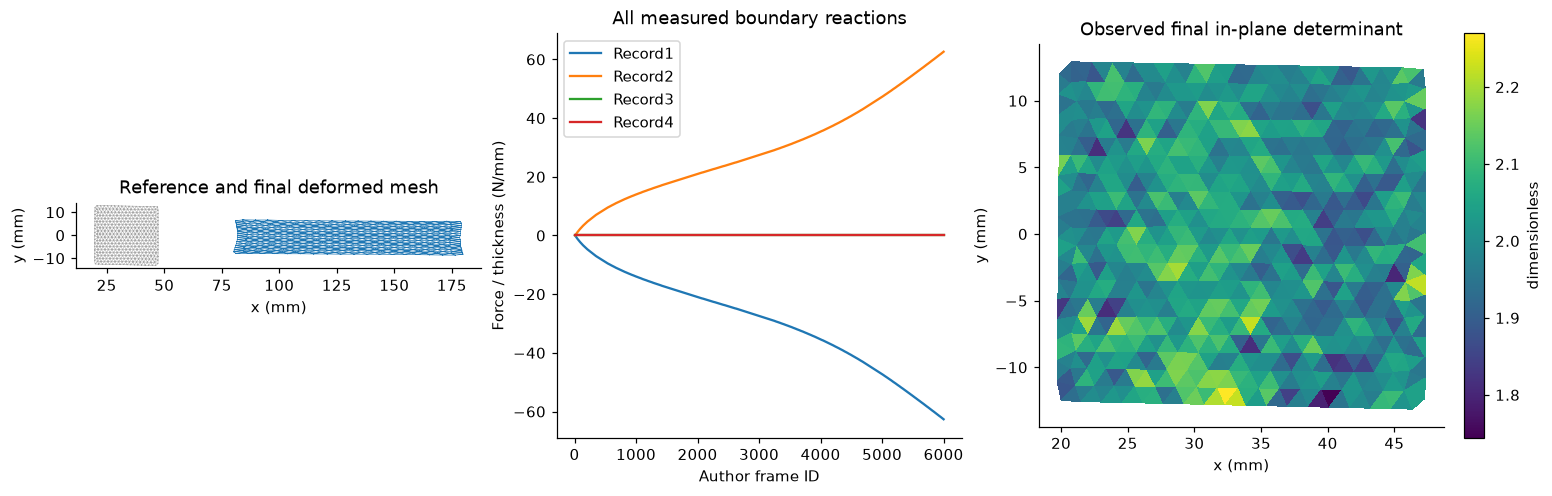

In [2]:
fig,axs=plt.subplots(1,3,figsize=(14,4.4),layout='constrained')
x=data['coordinates'];tri=data['triangles'];u=data['displacements'][-1]
axs[0].triplot(x[:,0],x[:,1],tri,lw=.35,color='.65');axs[0].triplot((x+u)[:,0],(x+u)[:,1],tri,lw=.45,color='tab:blue');axs[0].set_aspect('equal');axs[0].set(title='Reference and final deformed mesh',xlabel='x (mm)',ylabel='y (mm)')
for k in range(4):axs[1].plot(data['load_steps'],data['reactions'][:,k],label=f'Record{k+1}')
axs[1].set(title='All measured boundary reactions',xlabel='Author frame ID',ylabel='Force / thickness (N/mm)');axs[1].legend()
Ffinal=element_deformation(tri,data['shape_gradients'],u)
mesh_field(axs[2],data,np.linalg.det(Ffinal),'Observed final in-plane determinant','dimensionless')
plt.show()


## 2. Forward physics, active inverse, and independent evaluation

With calibrated triangle gradients g and displacements u, F=I+sum(u outer g). Incompressibility gives F33=1/det(F). The stored energy is W=Qtheta and the reduced derivative P=dW/dF includes pressure elimination under zero out-of-plane stress. Its dimensionless171-term dictionary combines20 invariant monomials, one logarithmic term, and150 stretch-power terms. Redundancy prevents a unique-coefficient interpretation.

The objective is the unnormalized sum of free-force squares plus20 times boundary-force residual squares, plus10000 times the nonnegative coefficient sum. The local solver assembles every frame, then performs nonnegative weighted-LS fixed-point updates with full working-set reentry. Its full projected KKT check includes inactive variables. Frozen parity arrays are never inputs to this reconstruction.

$$F_e=I+\sum_{a=1}^{3}u_{ea}\otimes g_{ea},\quad W(F)=Q(F)\theta,\quad P(F)=\frac{\partial W}{\partial F}.$$

Here e indexes triangles, a indexes local nodes, I is the2D identity, u is measured displacement, g is calibrated shape gradient, Q is the171-term dimensionless dictionary, and theta contains nonnegative MPa coefficients.

$$\min_{\theta\ge0}\sum_{t=1}^{600}\left(\|A_{\mathrm{free},t}\theta\|_2^2+20\|A_{\mathrm{boundary},t}\theta-r_t\|_2^2\right)+10000\|\theta\|_1.$$

Here t indexes observed frames, the two A operators integrate constitutive derivatives into free nodal or boundary-group forces, and r contains measured reactions. The numbers belong to the selected estimator, not additional sensor calibration.


In [3]:
theta,info,(H,b,C)=reconstruct(data)
np.savez_compressed('output/reconstruction.npz',reconstruction=theta[None])
report,exit_code=judge.evaluate('output/reconstruction.npz');print(json.dumps({'fresh':info,'judge':report},indent=2));assert exit_code==0
qualified=np.load('evaluation/baseline_reference.npz')
native=np.load('notebooks/reference_outputs/native_failed_baseline.npz')['output_theta']
native_single=np.load('notebooks/reference_outputs/native_single_lambda_selected.npz')['reconstruction'][0]
certificate=np.load('notebooks/reference_outputs/independent_certificate.npz')['reconstruction'][0]
reference_theta=qualified['reconstruction'][0]
print('Meaningful coefficients (>1e-7 MPa):',[(int(i),float(theta[i])) for i in np.where(theta>1e-7)[0]])


{
  "fresh": {
    "history": [
      [
        0.001,
        977,
        1.9584334154387761e-13
      ],
      [
        1e-05,
        802,
        1.4616086119190186e-13
      ],
      [
        1e-07,
        797,
        7.784328737159285e-13
      ],
      [
        1e-09,
        794,
        6.352696146905146e-13
      ],
      [
        1e-11,
        303,
        9.965273252132842e-13
      ],
      [
        1e-13,
        18,
        9.960920976936904e-13
      ]
    ],
    "projected_kkt": 1.541009197609942e-10,
    "seed": 0,
    "weak_sse": 34577.88329057023,
    "penalty": 5054.588807622698,
    "total": 39632.47209819293,
    "weak_residual_relative_l2": 0.03595078030944698,
    "seconds": 16.31368720001774
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "energy_relative_l2": 7.821410843653103e-15,
      "stress_relative_l2": 4.4149925569126995e-14,
      "weak_residual_relative_l2": 0.035950780309448885
    },
    "thresholds": {
 

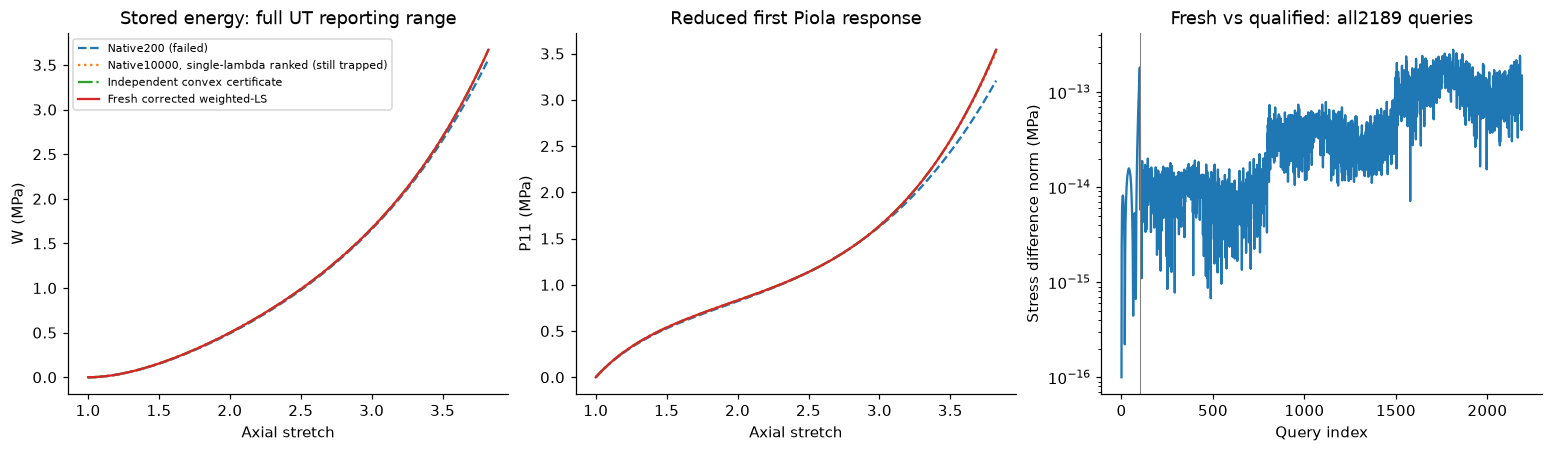

In [4]:
stretch=np.linspace(1,3.823,101);Fut=data['query_gradients'][:101]
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
groups=[('Native200 (failed)',native,'--'),('Native10000, single-lambda ranked (still trapped)',native_single,':'),('Independent convex certificate',certificate,'-.'),('Fresh corrected weighted-LS',theta,'-')]
for name,t,style in groups:
    W,P=law(Fut,t);axs[0].plot(stretch,W,style,label=name);axs[1].plot(stretch,P[:,0,0],style,label=name)
W,P=law(data['query_gradients'],theta);Wr,Pr=law(data['query_gradients'],reference_theta)
err=np.linalg.norm((P-Pr).reshape(-1,4),axis=1)
axs[2].semilogy(np.arange(2189),np.maximum(err,1e-16));axs[2].axvline(101,color='.5',lw=.7)
axs[0].set(title='Stored energy: full UT reporting range',xlabel='Axial stretch',ylabel='W (MPa)');axs[1].set(title='Reduced first Piola response',xlabel='Axial stretch',ylabel='P11 (MPa)');axs[2].set(title='Fresh vs qualified: all2189 queries',xlabel='Query index',ylabel='Stress difference norm (MPa)');axs[0].legend(fontsize=7)
plt.show()


## 3. Full-observation consistency and derived spatial response

The next calculation evaluates the recovered law against every measured frame again. It reports boundary reactions and unconstrained nodal-force residuals in physical units, without using a frame mask. These discrepancies are equilibrium/model/noise residuals, not independently calibrated noise likelihoods. The final spatial maps show the homogeneous law evaluated at heterogeneous observed deformation.

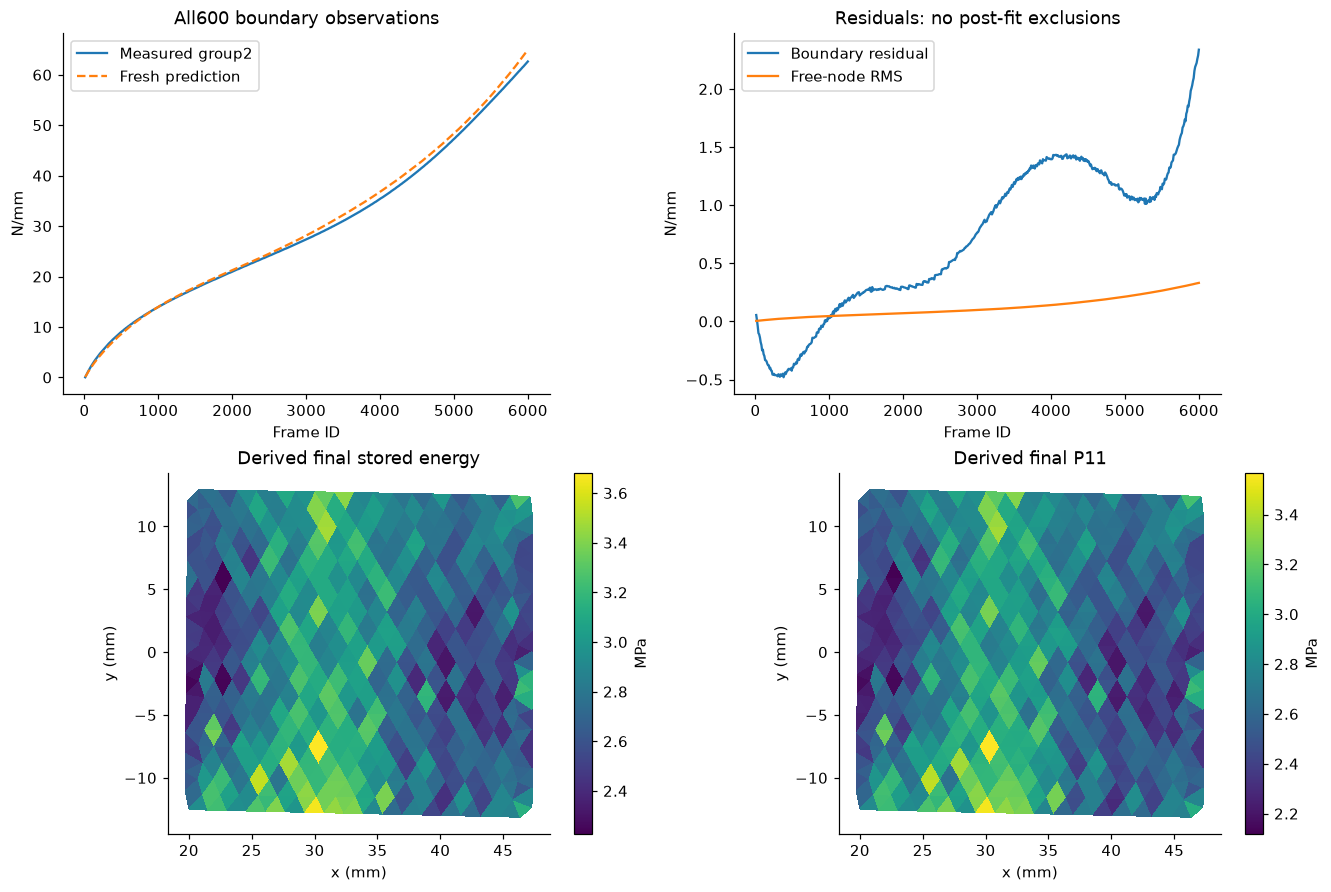

In [5]:
predicted,free_rms=forward_records(data,theta)
Wfinal,Pfinal=law(Ffinal,theta)
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
axs[0,0].plot(data['load_steps'],data['reactions'][:,1],label='Measured group2');axs[0,0].plot(data['load_steps'],predicted[:,1],'--',label='Fresh prediction');axs[0,0].set(title='All600 boundary observations',xlabel='Frame ID',ylabel='N/mm');axs[0,0].legend()
axs[0,1].plot(data['load_steps'],predicted[:,1]-data['reactions'][:,1],label='Boundary residual');axs[0,1].plot(data['load_steps'],free_rms,label='Free-node RMS');axs[0,1].set(title='Residuals: no post-fit exclusions',xlabel='Frame ID',ylabel='N/mm');axs[0,1].legend()
mesh_field(axs[1,0],data,Wfinal,'Derived final stored energy','MPa');mesh_field(axs[1,1],data,Pfinal[:,0,0],'Derived final P11','MPa')
plt.show()


## 4. Why native convergence was insufficient

The unmodified default source reproduced its original run but permanently removed coefficients below a cutoff. Merely raising its iteration cap did not repair support trapping. Its reporting/ranking function additionally counted the global penalty600 times, while its fixed-point equations used it once. Both criteria are shown rather than silently interchanged. Native max10000 candidates across three seeds are historical reproduced comparisons; they are not fresh local recovered results. The corrected IRLS floor stages below are fresh.

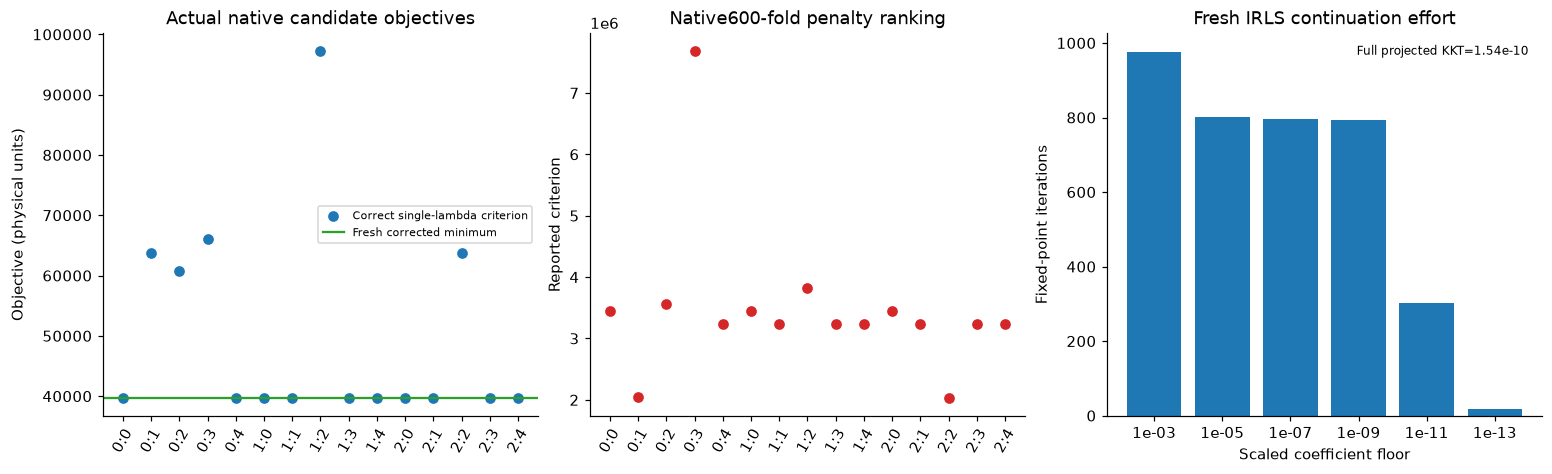

In [6]:
native_runs=json.loads(Path('notebooks/reference_outputs/native_multiseed_comparison.json').read_text())['seeds']
single=[];repeated=[];labels=[]
for row in native_runs:
    for c in row['candidates']:
        single.append(c['single_lambda_total']);repeated.append(c['native600lambda_total']);labels.append(f"{row['seed']}:{c['guess']}")
fig,axs=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
xids=np.arange(len(labels));axs[0].plot(xids,single,'o',label='Correct single-lambda criterion');axs[0].axhline(info['total'],label='Fresh corrected minimum',color='tab:green');axs[0].set(xticks=xids,xticklabels=labels,title='Actual native candidate objectives',ylabel='Objective (physical units)');axs[0].tick_params(axis='x',rotation=60);axs[0].legend(fontsize=7)
axs[1].plot(xids,repeated,'o',color='tab:red');axs[1].set(xticks=xids,xticklabels=labels,title='Native600-fold penalty ranking',ylabel='Reported criterion');axs[1].tick_params(axis='x',rotation=60)
h=np.array(info['history']);axs[2].bar(np.arange(len(h)),h[:,1]);axs[2].set(xticks=np.arange(len(h)),xticklabels=[f'{v:.0e}' for v in h[:,0]],title='Fresh IRLS continuation effort',xlabel='Scaled coefficient floor',ylabel='Fixed-point iterations');axs[2].text(.97,.97,f"Full projected KKT={info['projected_kkt']:.2e}",ha='right',va='top',transform=axs[2].transAxes,fontsize=8)
plt.show()


## 5. Physical invariance and identifiability

Rotating the observer must preserve energy and rotate first Piola stress. A central finite difference independently checks the analytical energy derivative. The normalized normal-matrix spectrum displays the dictionary's severe redundancy; tiny modes are not evidence for independent material parameters. Coefficient agreement is therefore not the primary acceptance criterion.

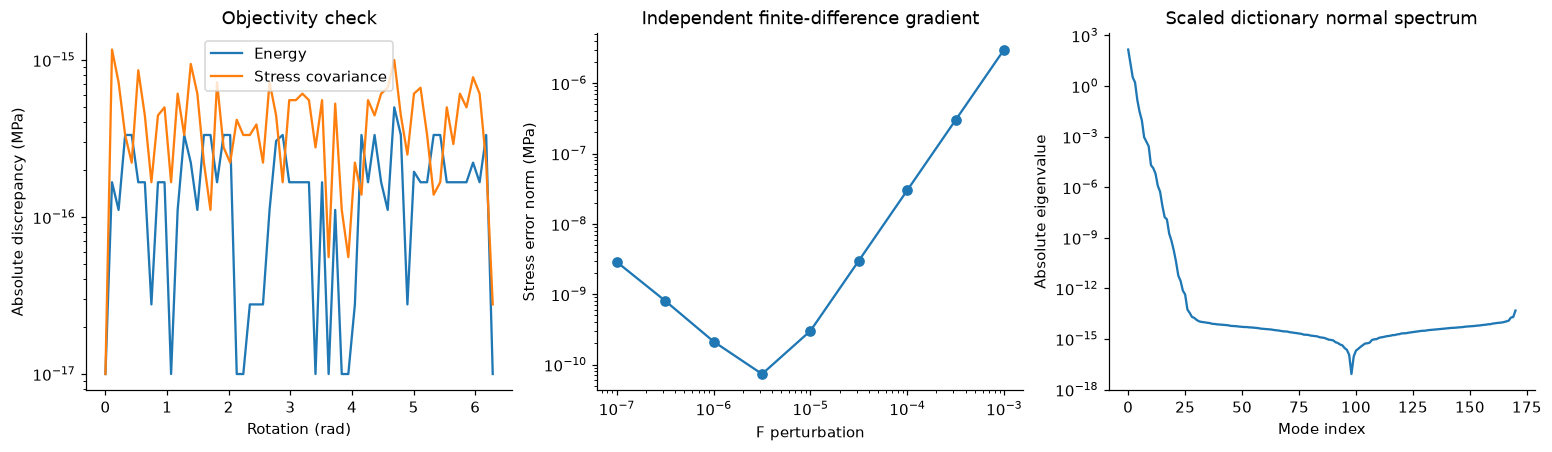

In [7]:
angle=np.linspace(0,2*np.pi,60);testF=np.array([[[1.6,.15],[.08,.7]]]);W0,P0=law(testF,theta);we=[];pe=[]
for a in angle:
    R=np.array([[np.cos(a),-np.sin(a)],[np.sin(a),np.cos(a)]]);w,p=law(R@testF,theta);we.append(abs(w[0]-W0[0]));pe.append(np.max(abs(p[0]-R@P0[0])))
steps=np.logspace(-3,-7,9);fd_errors=[]
for eps in steps:
    fd=[]
    for k in range(4):
        E=np.zeros(4);E[k]=eps;E=E.reshape(2,2);fd.append((law(testF+E,theta)[0][0]-law(testF-E,theta)[0][0])/(2*eps))
    fd_errors.append(np.linalg.norm(np.array(fd)-P0.reshape(4)))
scale=np.sqrt(np.diag(H));eig=np.linalg.eigvalsh(H/scale[:,None]/scale[None,:])
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
axs[0].semilogy(angle,np.maximum(we,1e-17),label='Energy');axs[0].semilogy(angle,np.maximum(pe,1e-17),label='Stress covariance');axs[0].set(title='Objectivity check',xlabel='Rotation (rad)',ylabel='Absolute discrepancy (MPa)');axs[0].legend()
axs[1].loglog(steps,fd_errors,'o-');axs[1].set(title='Independent finite-difference gradient',xlabel='F perturbation',ylabel='Stress error norm (MPa)')
axs[2].semilogy(np.arange(171),np.maximum(abs(eig[::-1]),1e-18));axs[2].set(title='Scaled dictionary normal spectrum',xlabel='Mode index',ylabel='Absolute eigenvalue');plt.show()


## 6. Regularization and restricted-model ablations

Two other penalty values are actually fitted on the same freshly assembled all600 normal system. Simple neo-Hookean and Mooney–Rivlin dictionary restrictions are also independently fitted by nonnegative least squares, with no regularization. These are transparent ablations, not claims to reproduce all nonlinear fits or FE simulations in the paper. Their weaker representational capacity and different objectives are explicitly identified.

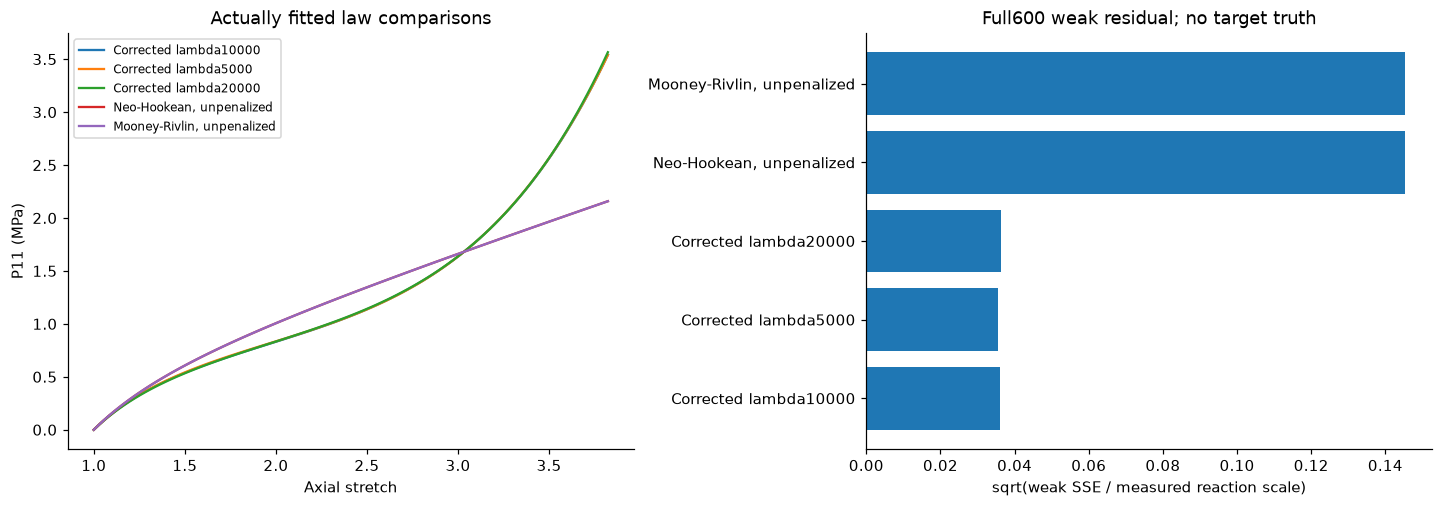

In [8]:
experiments=[('Corrected lambda10000',theta,info['weak_sse'])]
for penalty in [5000.,20000.]:
    t,diag=solve(H,b,C,penalty=penalty);experiments.append((f'Corrected lambda{penalty:g}',t,objective(t,H,b,C,penalty)['weak_sse']))
for name,ids in [('Neo-Hookean, unpenalized',[0]),('Mooney-Rivlin, unpenalized',[0,1])]:
    t=np.zeros(171);ids=np.array(ids);t[ids],_=positive_quadratic(H[np.ix_(ids,ids)],b[ids]);experiments.append((name,t,objective(t,H,b,C,penalty=0)['weak_sse']))
fig,axs=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for name,t,cost in experiments:axs[0].plot(stretch,law(Fut,t)[1][:,0,0],label=name)
axs[0].set(title='Actually fitted law comparisons',xlabel='Axial stretch',ylabel='P11 (MPa)');axs[0].legend(fontsize=8)
axs[1].barh([name for name,_,_ in experiments],[np.sqrt(v/C) for _,_,v in experiments]);axs[1].set(title='Full600 weak residual; no target truth',xlabel='sqrt(weak SSE / measured reaction scale)');plt.show()


## 7. Force-calibration robustness and independent starts

A controlled ±2% load-cell calibration perturbation scales every one of the600 reaction records. The same full600 displacement observations and geometry remain fixed. Since the complete unnormalized normal system has already been actively assembled, its reaction-linear RHS and reaction-quadratic constant can be scaled exactly; no recovery is cached. Each perturbed problem is solved anew. Three new local starts test convergence under the same declared model; these experiments do not enlarge a scientific accuracy claim beyond the announced domain.

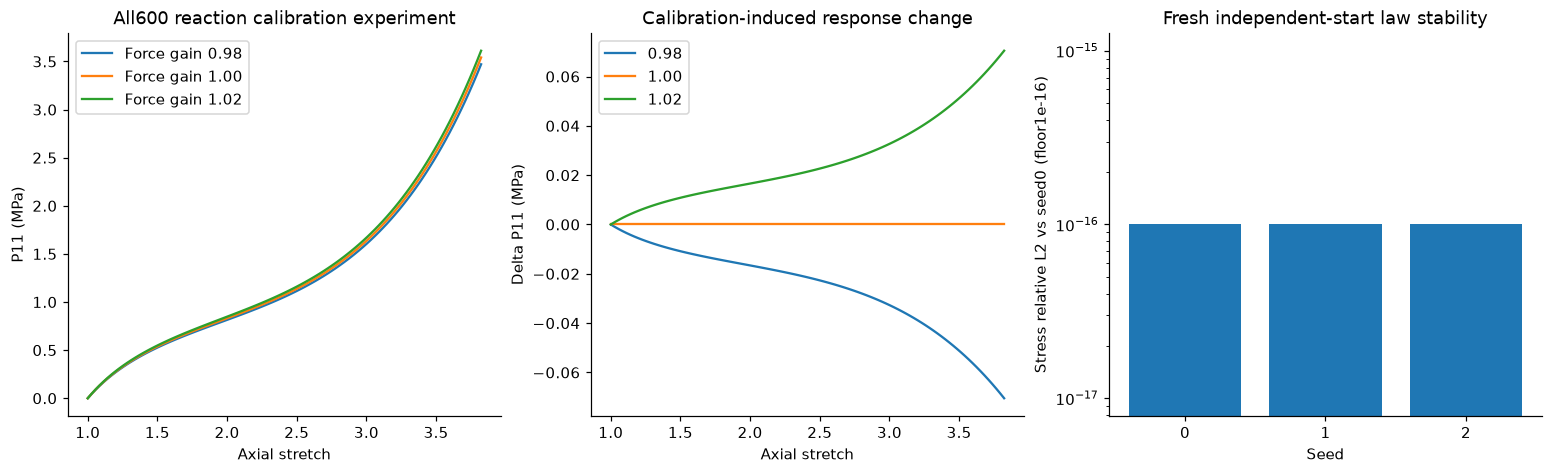

Exact start differences: [0.0, np.float64(0.0), np.float64(0.0)]


In [9]:
calibration=[]
for gain in [.98,1.,1.02]:
    t,dg=solve(H,b*gain,C*gain**2);calibration.append((gain,t))
local_starts=[]
for seed in [1,2]:
    t,dg=solve(H,b,C,seed=seed);local_starts.append((seed,t,dg['projected_kkt']))
fig,axs=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
for gain,t in calibration:axs[0].plot(stretch,law(Fut,t)[1][:,0,0],label=f'Force gain {gain:.2f}')
axs[0].set(title='All600 reaction calibration experiment',xlabel='Axial stretch',ylabel='P11 (MPa)');axs[0].legend()
for gain,t in calibration:axs[1].plot(stretch,(law(Fut,t)[1][:,0,0]-law(Fut,theta)[1][:,0,0]),label=f'{gain:.2f}')
axs[1].set(title='Calibration-induced response change',xlabel='Axial stretch',ylabel='Delta P11 (MPa)');axs[1].legend()
diffs=[0.]+[np.linalg.norm(law(data['query_gradients'],t)[1]-P)/np.linalg.norm(P) for _,t,_ in local_starts]
axs[2].bar([0,1,2],np.maximum(diffs,1e-16));axs[2].set_yscale('log');axs[2].set(xticks=[0,1,2],title='Fresh independent-start law stability',xlabel='Seed',ylabel='Stress relative L2 vs seed0 (floor1e-16)');plt.show()
print('Exact start differences:',diffs)


## 8. Evidence ledger and interpretation

All reconstruction, response, residual, ablation and robustness curves above were computed in this execution. The qualified result is a **conditional fixed-penalty material law**, supported by independent source-operator parity and a convex optimality certificate. Native source failure is visible, and no cached output was presented as fresh. There is no measured true energy or stress field, no unique-coefficient claim, and no validated extrapolation beyond the announced acquisition/reporting domain. Controlled calibration sensitivity is not a noise-calibrated confidence interval. Data rights and the absence of a source-code license remain applicable.

In [10]:
summary={'active600_reconstruction_seconds':info['seconds'],'judge':report,'native_failed_weak':objective(native,H,b,C),'fresh_weak':objective(theta,H,b,C),'local_start_stress_relative_l2':diffs,'all600_frames_used':len(data['displacements']),'all_query_gradients_used':len(data['query_gradients'])}
print(json.dumps(summary,indent=2,allow_nan=False))
Path('output/notebook_measurements.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')


{
  "active600_reconstruction_seconds": 16.31368720001774,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "energy_relative_l2": 7.821410843653103e-15,
      "stress_relative_l2": 4.4149925569126995e-14,
      "weak_residual_relative_l2": 0.035950780309448885
    },
    "thresholds": {
      "energy_relative_l2": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "stress_relative_l2": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "weak_residual_relative_l2": {
        "comparison": "<=",
        "boundary": 0.036310288113492045
      }
    },
    "errors": []
  },
  "native_failed_weak": {
    "weak_sse": 54917.40760211274,
    "penalty": 5831.942067710026,
    "total": 60749.34966982277,
    "weak_residual_relative_l2": 0.04530687760328818
  },
  "fresh_weak": {
    "weak_sse": 34577.88329057023,
    "penalty": 5054.588807622698,
    "total": 39632.47209819293,
    "weak_residual_relative_l2": 0.035950780309446

1142